In [1]:
import cv2
import pandas as pd
import numpy as np
from pathlib import Path
from tqdm import tqdm
import matplotlib.pyplot as plt

In [3]:
from pathlib import Path

cwd = Path.cwd()

if (cwd / "datasets" / "Celeb-DF-v2").exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / "datasets" / "Celeb-DF-v2").exists():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError(
        "Could not find datasets/Celeb-DF-v2. "
        "Make sure notebook is inside the notebooks folder."
    )

DATASET_DIR = PROJECT_ROOT / "datasets" / "Celeb-DF-v2"
RESULTS_DIR = PROJECT_ROOT / "results"

PROCESSED_DIR = RESULTS_DIR / "processed_faces"

print("Project:", PROJECT_ROOT)
print("Dataset:", DATASET_DIR)
print("Processed faces:", PROCESSED_DIR)

Project: c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE DETECTION
Dataset: c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE DETECTION\datasets\Celeb-DF-v2
Processed faces: c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE DETECTION\results\processed_faces


In [4]:
# load metadata
metadata_path = RESULTS_DIR / "cleaned_video_metadata.csv"

if not metadata_path.exists():
    raise FileNotFoundError(
        f"Metadata file not found: {metadata_path}"
    )

cleaned_metadata_df = pd.read_csv(metadata_path)

print("Shape:", cleaned_metadata_df.shape)
display(cleaned_metadata_df.head())



Shape: (6529, 11)


,video_path,filename,folder,fps,frame_count,width,height,duration,label,class_name,resolution
0,..\datasets\Celeb-DF-v2\Celeb-real\id0_0000.mp4,id0_0000.mp4,Celeb-real,30.0,469.0,942.0,500.0,15.633333,0,Real,942x500
1,..\datasets\Celeb-DF-v2\Celeb-real\id0_0001.mp4,id0_0001.mp4,Celeb-real,30.0,303.0,942.0,500.0,10.100000,0,Real,942x500
2,..\datasets\Celeb-DF-v2\Celeb-real\id0_0002.mp4,id0_0002.mp4,Celeb-real,30.0,350.0,942.0,500.0,11.666667,0,Real,942x500
3,..\datasets\Celeb-DF-v2\Celeb-real\id0_0003.mp4,id0_0003.mp4,Celeb-real,30.0,529.0,942.0,500.0,17.633333,0,Real,942x500
4,..\datasets\Celeb-DF-v2\Celeb-real\id0_0004.mp4,id0_0004.mp4,Celeb-real,30.0,326.0,942.0,500.0,10.866667,0,Real,942x500


In [5]:
# check columns 
print(cleaned_metadata_df.columns.tolist())

['video_path', 'filename', 'folder', 'fps', 'frame_count', 'width', 'height', 'duration', 'label', 'class_name', 'resolution']


In [6]:
# check label 
print(cleaned_metadata_df["label"].value_counts())

if "class_name" in cleaned_metadata_df.columns:
    print("\nClass names:")
    print(cleaned_metadata_df["class_name"].value_counts())

label
1    5639
0     890
Name: count, dtype: int64

Class names:
class_name
Deepfake    5639
Real         890
Name: count, dtype: int64


In [7]:
# extraction setting 
FRAMES_PER_VIDEO = 10
TARGET_SIZE = (224, 224)
FACE_PADDING = 0.20

print("Frames per video:", FRAMES_PER_VIDEO)
print("Target size:", TARGET_SIZE)
print("Face padding:", FACE_PADDING)

Frames per video: 10
Target size: (224, 224)
Face padding: 0.2


In [8]:
# Haar Cascade
FRAMES_PER_VIDEO = 10

CASCADE_PATH = PROJECT_ROOT / "notebooks" / "haarcascade_frontalface_default.xml"

if not CASCADE_PATH.exists():
    raise FileNotFoundError(
        f"Haar Cascade not found: {CASCADE_PATH}"
    )

face_cascade = cv2.CascadeClassifier(str(CASCADE_PATH))

if face_cascade.empty():
    raise RuntimeError("Failed to load Haar Cascade.")

print("Face detector loaded successfully.")

Face detector loaded successfully.


In [9]:
# face detection function

def detect_faces(frames):
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.05,
        minNeighbors=3,
        minSize=(30, 30)
    )

    return faces

In [10]:
# face cropping 
def crop_face_with_padding(frame, box, padding=0.20):
    x, y, w, h = box

    pad_x = int(w * padding)
    pad_y = int(h * padding)

    x1 = max(0, x - pad_x)
    y1 = max(0, y - pad_y)

    x2 = min(frame.shape[1], x + w + pad_x)
    y2 = min(frame.shape[0], y + h + pad_y)

    face = frame[y1:y2, x1:x2]

    return face


In [11]:
# video se faces extract
def extract_faces_from_video(
    video_path,
    num_frames=10,
    target_size=(224, 224),
    padding=0.20
):
    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        return []

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if total_frames <= 0:
        cap.release()
        return []

    frame_indices = np.linspace(
        0,
        total_frames - 1,
        num_frames,
        dtype=int
    )

    extracted_faces = []

    for frame_idx in frame_indices:

        cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_idx))

        success, frame = cap.read()

        if not success:
            continue

        faces = detect_faces(frame)

        if len(faces) == 0:
            continue

        # Largest face
        largest_face = max(
            faces,
            key=lambda box: box[2] * box[3]
        )

        face = crop_face_with_padding(
            frame,
            largest_face,
            padding
        )

        if face.size == 0:
            continue

        face = cv2.resize(face, target_size)

        extracted_faces.append(face)

    cap.release()

    return extracted_faces

# day 8

In [12]:
# first 5 video 

test_df = cleaned_metadata_df.head(5)

for _, row in test_df.iterrows():

    video_path = PROJECT_ROOT / row["video_path"]

    print("\nVideo:", video_path)

    faces = extract_faces_from_video(
        video_path,
        num_frames=FRAMES_PER_VIDEO,
        target_size=TARGET_SIZE,
        padding=FACE_PADDING
    )

    print("Faces extracted:", len(faces))


Video: c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE DETECTION\..\datasets\Celeb-DF-v2\Celeb-real\id0_0000.mp4
Faces extracted: 0

Video: c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE DETECTION\..\datasets\Celeb-DF-v2\Celeb-real\id0_0001.mp4
Faces extracted: 0

Video: c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE DETECTION\..\datasets\Celeb-DF-v2\Celeb-real\id0_0002.mp4
Faces extracted: 0

Video: c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE DETECTION\..\datasets\Celeb-DF-v2\Celeb-real\id0_0003.mp4
Faces extracted: 0

Video: c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE DETECTION\..\datasets\Celeb-DF-v2\Celeb-real\id0_0004.mp4
Faces extracted: 0


In [13]:
# Check one video properly

row = cleaned_metadata_df.iloc[0]

print("Metadata video_path:")
print(repr(row["video_path"]))

video_path = PROJECT_ROOT / row["video_path"]

print("\nFinal video path:")
print(video_path)

print("\nDoes file exist?")
print(video_path.exists())

cap = cv2.VideoCapture(str(video_path))

print("\nVideo opened?")
print(cap.isOpened())

frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
print("Frame count:", frame_count)

success, frame = cap.read()

print("Frame read successfully?", success)

if success:
    print("Frame shape:", frame.shape)

    faces = detect_faces(frame)

    print("Faces detected in first frame:", len(faces))

cap.release()

Metadata video_path:
'..\\datasets\\Celeb-DF-v2\\Celeb-real\\id0_0000.mp4'

Final video path:
c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE DETECTION\..\datasets\Celeb-DF-v2\Celeb-real\id0_0000.mp4

Does file exist?
False

Video opened?
False
Frame count: -1
Frame read successfully? False


In [14]:
# Fix video paths

from pathlib import Path

def fix_video_path(path_string):
    path = Path(str(path_string))

    # Remove leading ".." if metadata paths were created
    # relative to the notebooks folder
    if path.parts and path.parts[0] == "..":
        path = Path(*path.parts[1:])

    return PROJECT_ROOT / path


cleaned_metadata_df["full_video_path"] = (
    cleaned_metadata_df["video_path"]
    .apply(fix_video_path)
)

print(cleaned_metadata_df["full_video_path"].iloc[0])
print(
    "Exists:",
    cleaned_metadata_df["full_video_path"].iloc[0].exists()
)

c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE DETECTION\datasets\Celeb-DF-v2\Celeb-real\id0_0000.mp4
Exists: True


In [15]:
video_path = cleaned_metadata_df["full_video_path"].iloc[0]

print("Video:", video_path)
print("Exists:", video_path.exists())

cap = cv2.VideoCapture(str(video_path))

print("Video opened:", cap.isOpened())

success, frame = cap.read()

print("Frame read:", success)

if success:
    print("Frame shape:", frame.shape)

    faces = detect_faces(frame)

    print("Faces detected:", len(faces))

cap.release()

Video: c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE DETECTION\datasets\Celeb-DF-v2\Celeb-real\id0_0000.mp4
Exists: True
Video opened: True
Frame read: True
Frame shape: (500, 942, 3)
Faces detected: 1


In [16]:
# Visual check
sample_faces = []

for _, row in test_df.iterrows():

    video_path = PROJECT_ROOT / row["video_path"]

    faces = extract_faces_from_video(
        video_path,
        num_frames=FRAMES_PER_VIDEO,
        target_size=TARGET_SIZE,
        padding=FACE_PADDING
    )

    sample_faces.extend(faces[:2])

    if len(sample_faces) >= 6:
        break


    plt.figure(figsize=(12, 8))

for i, face in enumerate(sample_faces[:6]):

    plt.subplot(2, 3, i + 1)

    face_rgb = cv2.cvtColor(face, cv2.COLOR_BGR2RGB)

    plt.imshow(face_rgb)
    plt.axis("off")
    plt.title(f"Face {i+1}")

plt.tight_layout()
plt.show()

<Figure size 1200x800 with 0 Axes>

<Figure size 1200x800 with 0 Axes>

<Figure size 1200x800 with 0 Axes>

<Figure size 1200x800 with 0 Axes>

<Figure size 1200x800 with 0 Axes>

# DAY 9 save extracted faces


In [17]:
REAL_DIR = PROCESSED_DIR / "real"
FAKE_DIR = PROCESSED_DIR / "deepfake"

REAL_DIR.mkdir(parents=True, exist_ok=True)
FAKE_DIR.mkdir(parents=True, exist_ok=True)

print("Folders created.")

Folders created.


In [18]:
# full extraction
extraction_records = []

for idx, row in tqdm(
    cleaned_metadata_df.iterrows(),
    total=len(cleaned_metadata_df),
    desc="Extracting faces"
):

    video_path = row["full_video_path"]

    label = int(row["label"])

    if label == 0:
        output_dir = REAL_DIR
        class_name = "real"
    else:
        output_dir = FAKE_DIR
        class_name = "deepfake"

    faces = extract_faces_from_video(
        video_path,
        num_frames=FRAMES_PER_VIDEO,
        target_size=TARGET_SIZE,
        padding=FACE_PADDING
    )

    video_id = Path(row["full_video_path"]).stem

    for face_idx, face in enumerate(faces):

        filename = f"{video_id}_face_{face_idx:02d}.jpg"

        output_path = output_dir / filename

        cv2.imwrite(
            str(output_path),
            face
        )

        extraction_records.append({
            "video_path": str(row["full_video_path"]),
            "video_id": video_id,
            "face_path": str(output_path.relative_to(PROJECT_ROOT)),
            "label": label,
            "class_name": class_name
        })

Extracting faces: 100%|██████████| 6529/6529 [1:09:24<00:00,  1.57it/s]


In [20]:
# Save extrcation metadata
face_metadata_df = pd.DataFrame(extraction_records)

face_metadata_path = RESULTS_DIR / "final_face_metadata.csv"

face_metadata_df.to_csv(
    face_metadata_path,
    index=False
)

print("Face metadata saved:")
print(face_metadata_path)

print("\nShape:", face_metadata_df.shape)

display(face_metadata_df.head())

Face metadata saved:
c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE DETECTION\results\final_face_metadata.csv

Shape: (61641, 5)


,video_path,video_id,face_path,label,class_name
0,c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE...,id0_0000,results\processed_faces\real\id0_0000_face_00.jpg,0,real
1,c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE...,id0_0000,results\processed_faces\real\id0_0000_face_01.jpg,0,real
2,c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE...,id0_0000,results\processed_faces\real\id0_0000_face_02.jpg,0,real
3,c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE...,id0_0000,results\processed_faces\real\id0_0000_face_03.jpg,0,real
4,c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE...,id0_0000,results\processed_faces\real\id0_0000_face_04.jpg,0,real


# day 10


In [21]:
# face dataset quality checking
face_metadata_df["file_exists"] = face_metadata_df["face_path"].apply(
    lambda x: (PROJECT_ROOT / x).exists()
)

print(face_metadata_df["file_exists"].value_counts())

file_exists
True    61641
Name: count, dtype: int64


In [22]:
# check image dimension
def get_image_size(relative_path):

    path = PROJECT_ROOT / relative_path

    image = cv2.imread(str(path))

    if image is None:
        return None

    return image.shape[:2] 



face_metadata_df["image_size"] = face_metadata_df["face_path"].apply(
    get_image_size
)

print(face_metadata_df["image_size"].value_counts().head())

image_size
(224, 224)    61641
Name: count, dtype: int64


# day 11

In [23]:
#video level split
#data leakage avoid karenge
#Unique videos

video_df = face_metadata_df[
    ["video_path", "video_id", "label", "class_name"]
].drop_duplicates()

video_df = video_df.reset_index(drop=True)

print("Unique videos:", len(video_df))
display(video_df.head())


Unique videos: 6165


,video_path,video_id,label,class_name
0,c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE...,id0_0000,0,real
1,c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE...,id0_0001,0,real
2,c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE...,id0_0002,0,real
3,c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE...,id0_0003,0,real
4,c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE...,id0_0004,0,real


In [24]:
# train/test split
from sklearn.model_selection import train_test_split
train_videos, test_videos = train_test_split(
    video_df,
    test_size=0.20,
    random_state=42,
    stratify=video_df["label"]
)

train_videos, val_videos = train_test_split(
    train_videos,
    test_size=0.20,
    random_state=42,
    stratify=train_videos["label"]
)

print("Train videos:", len(train_videos))
print("Validation videos:", len(val_videos))
print("Test videos:", len(test_videos))

Train videos: 3945
Validation videos: 987
Test videos: 1233


In [25]:
# Create split mapping
train_videos = train_videos.copy()
val_videos = val_videos.copy()
test_videos = test_videos.copy()

train_videos["split"] = "train"
val_videos["split"] = "val"
test_videos["split"] = "test"

video_split_df = pd.concat(
    [train_videos, val_videos, test_videos],
    ignore_index=True
)

display(video_split_df.head())

,video_path,video_id,label,class_name,split
0,c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE...,id17_id0_0007,1,deepfake,train
1,c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE...,id43_id42_0007,1,deepfake,train
2,c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE...,id43_id47_0001,1,deepfake,train
3,c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE...,id4_id31_0006,1,deepfake,train
4,c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE...,id16_id1_0001,1,deepfake,train


In [26]:
# add split to face metedata
face_metadata_df = face_metadata_df.drop(
    columns=["split"],
    errors="ignore"
)

face_metadata_df = face_metadata_df.merge(
    video_split_df[
        ["video_id", "split"]
    ],
    on="video_id",
    how="left"
)

print(face_metadata_df["split"].value_counts())


split
train    39450
test     12321
val       9870
Name: count, dtype: int64


# DAY 12

In [27]:
#Leakage verification
split_check = (
    face_metadata_df
    .groupby("video_id")["split"]
    .nunique()
)

print(
    "Videos appearing in multiple splits:",
    (split_check > 1).sum()
)

Videos appearing in multiple splits: 0


class_name,deepfake,real
split,,
test,10610,1711
train,33930,5520
val,8490,1380


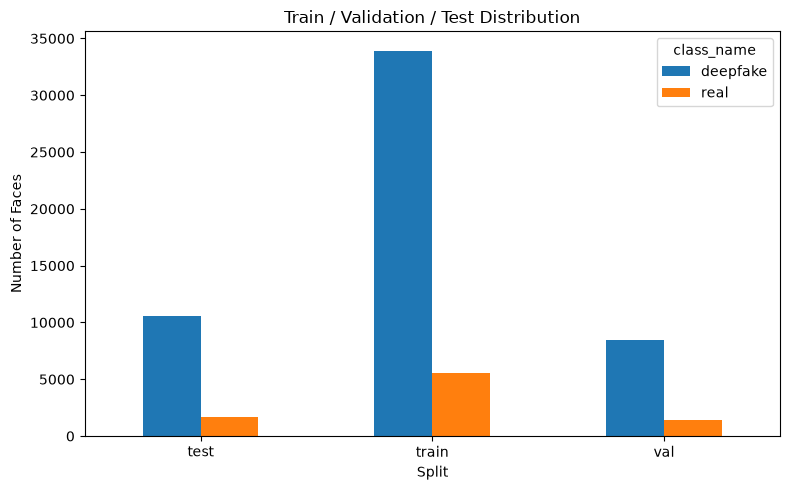

In [28]:
#class distribution
split_distribution = pd.crosstab(
    face_metadata_df["split"],
    face_metadata_df["class_name"]
)

display(split_distribution)

split_distribution.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Train / Validation / Test Distribution")
plt.xlabel("Split")
plt.ylabel("Number of Faces")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# DAY 13

In [29]:
# save final metadata

final_metadata_path = RESULTS_DIR / "final_face_metadata.csv"

face_metadata_df.to_csv(
    final_metadata_path,
    index=False
)

video_split_path = RESULTS_DIR / "video_split_metadata.csv"

video_split_df.to_csv(
    video_split_path,
    index=False
)

print("Saved:")
print(final_metadata_path)
print(video_split_path)

Saved:
c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE DETECTION\results\final_face_metadata.csv
c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE DETECTION\results\video_split_metadata.csv


# DAY 14

In [30]:
#pytorch dataset preparation
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

In [31]:
# transform
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [32]:
val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [33]:
# dataset class
class DeepfakeDataset(Dataset):

    def __init__(self, dataframe, transform=None):

        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):

        row = self.df.iloc[index]

        image_path = PROJECT_ROOT / row["face_path"]

        image = Image.open(image_path).convert("RGB")

        label = int(row["label"])

        if self.transform:
            image = self.transform(image)

        return image, label

In [34]:
# create datasets
train_df = face_metadata_df[
    face_metadata_df["split"] == "train"
].copy()

val_df = face_metadata_df[
    face_metadata_df["split"] == "val"
].copy()

test_df = face_metadata_df[
    face_metadata_df["split"] == "test"
].copy()

print("Train faces:", len(train_df))
print("Validation faces:", len(val_df))
print("Test faces:", len(test_df))

Train faces: 39450
Validation faces: 9870
Test faces: 12321


In [35]:
#pytorch dataset
train_dataset = DeepfakeDataset(
    train_df,
    transform=train_transform
)

val_dataset = DeepfakeDataset(
    val_df,
    transform = val_test_transform
)

test_dataset = DeepfakeDataset(
    test_df,
    transform=val_test_transform
)

print("Datasets created successfully.")

Datasets created successfully.


In [36]:
#dataLoader
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


In [ ]:
# final test
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Labels:", labels[:10])

c:\Users\Raja Kumar\anaconda3\envs\fastapi_env\Lib\site-packages\torch\utils\data\dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
